In [1]:
import Pkg

project_dir = let dir = pwd()
    while !isfile(joinpath(dir, "Project.toml")) && dirname(dir) != dir
        dir = dirname(dir)
    end
    isfile(joinpath(dir, "Project.toml")) || error("No se encontró Project.toml; abre el notebook desde el repositorio.")
    dir
end

Pkg.activate(project_dir)

import Plots
import DifferentialEquations as DE

using LinearAlgebra
using OptimalControl
using NLPModelsIpopt

  Activating project at `c:\Users\Matias\guiado-proyectiles`


In [2]:
# Datos

A = [
    0.0 1.0 0.0 0.0;
    0.0 0.0 0.0 0.0;
    0.0 0.0 0.0 1.0;
    0.0 0.0 0.0 0.0
]

B = [
    0.0 0.0;
    1.0 0.0;
    0.0 0.0;
    0.0 1.0
]

4×2 Matrix{Float64}:
 0.0  0.0
 1.0  0.0
 0.0  0.0
 0.0  1.0

### Forma analítica

In [3]:
function ganancias_analiticas(τ::Real, b::Real, c::Real)
    A_prima = [
        -1/3*b*τ^3  -1/2*c*τ^2   0.0         1/2*c*τ^2 ;
        -1/2*b*τ^2  -c*τ         0.0         c*τ       ;
        0.0         1/2*c*τ^2    -1/3*b*τ^3  -1/2*c*τ^2;
        0.0         c*τ          -1/2*b*τ^2  -c*τ
    ]

    B_prima = [
        1.0  τ    0.0  0.0;
        0.0  1.0  0.0  0.0;
        0.0  0.0  1.0  τ  ;
        0.0  0.0  0.0  1.0
    ]

    S = [
        1/2*c*τ^2,
        c*τ,
        -1/2*c*τ^2,
        -c*τ
    ]

    M = [
        b*τ   c  0.0  -c;
        0.0  -c  b*τ  c
    ]

    inversa = inv(I - A_prima)
    K = M * inversa * B_prima
    V = M * inversa * S + [-c, c]

    return K, V
end


function control_analitico(x, t, p)
    A_prima, B_prima, tf, b, c, r = p
    τ = max(tf - t, 0.0)
    K, V = ganancias_analiticas(τ, b, c)
    return -(K * x + V * r)
end


function dinamica_analitica!(dx, x, p, t)
    A_prima, B_prima, tf, b, c, r = p
    u = control_analitico(x, t, p)
    dx .= A_prima * x + B_prima * u
end


function simular_analitico(x0, tf::Real, Vm::Real, theta::Real, b::Real, c::Real)
    r = Vm * deg2rad(theta)
    p = (A, B, tf, b, c, r)

    prob = DE.ODEProblem(
        dinamica_analitica!, x0, (0, tf), p
    )  # Asumimos siempre que parte desde t0 = 0

    sol = DE.solve(prob; saveat=range(0, tf; length=201))
    return sol
end

simular_analitico (generic function with 1 method)

### Forma numérica

In [4]:
function simular_numerico(x0, tf::Real, Vm::Real, theta::Real, b::Real, c::Real)
    r = Vm * deg2rad(theta)

    @def ocp begin
        t ∈ [0, tf], time
        x ∈ R^4, state
        u ∈ R^2, control

        x(0) == x0

        # Escribimos directamente el resultado de multiplicar las matrices del problema
        ẋ(t) == [x[2](t), u[1](t), x[4](t), u[2](t)]

        0.5 * (
            b * (x[1](tf)^2 + x[3](tf)^2) +
            c * (x[2](tf) - x[4](tf) - r)^2
        ) + 0.5 * ∫( u[1](t)^2 + u[2](t)^2 ) → min
    end

    sol = OptimalControl.solve(ocp; grid_size=200)

    return sol
end

simular_numerico (generic function with 1 method)

## Experimentos

▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 200)
   ├─ Modeler: adnlp
   └─ Solver: ipopt

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     2804
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:      405

Total number of variables............................:     1204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:      804
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints

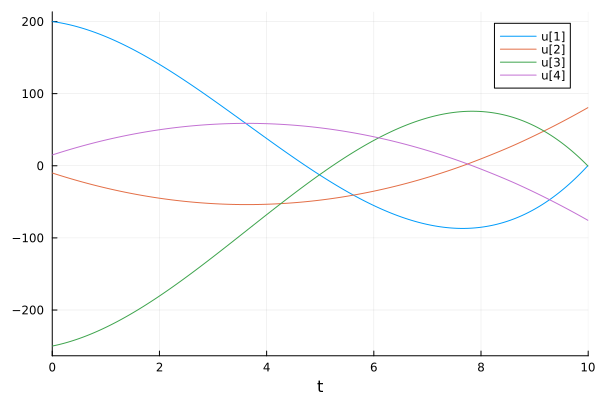

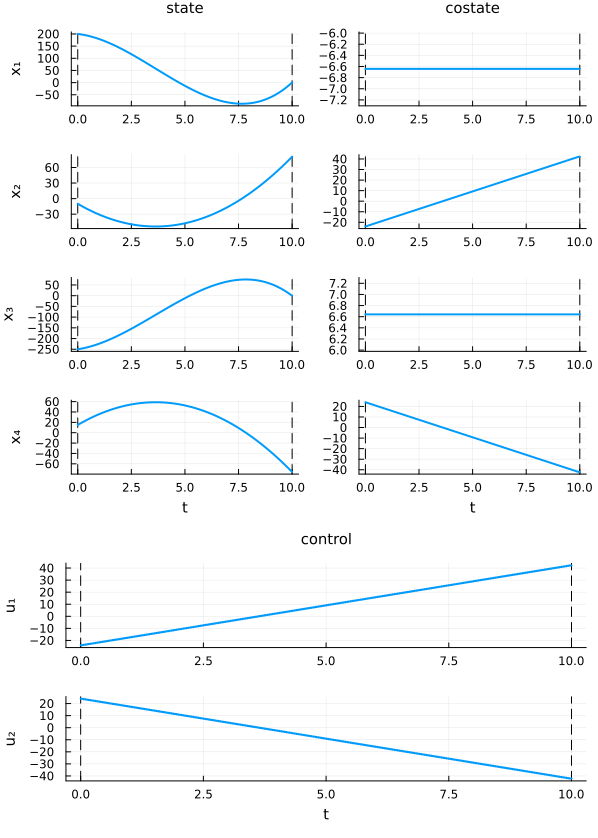

In [5]:
Vm = 300.0
tf = 10.0
x0_base = [200.0, -10.0, -250.0, 15.0]
theta_base = 30.0
b_base = 10.0
c_base = 100.0

sol_analitica = simular_analitico(x0_base, tf, Vm, theta_base, b_base, c_base)
sol_numerica = simular_numerico(x0_base, tf, Vm, theta_base, b_base, c_base)

display(Plots.plot(sol_analitica))

display(Plots.plot(sol_numerica))

In [6]:
pos_proyectil_1 = [
    [0.0, 0.0, 0.0],  # Son de la forma (x, y, θ)
    [0.0, 200.0, 0.0],
    [0.0, 2000.0, 0.0],
]
pos_proyectil_2 = [
    [0.0, 0.0, 0.0], 
    [0.0, -200.0, 0.0],
    [0.0, -2000.0, 0.0],
]
pos_proyectil_1 = pos_proyectil_1[2]
pos_proyectil_2 = pos_proyectil_2[2]
rapidez_proyectiles = 300.0

pos_objetivo = [10000.0, 0.0]

angulos_ref = [15.0, 30.0, 60.0, 90.0, 120.0, 150.0]

# El tiempo de impacto se obtiene de la aproximación lineal de la trayectoria
tf = (pos_objetivo[1] - pos_proyectil_1[1]) / rapidez_proyectiles

b_base = 1000.0
c_base = 10.0

function comparacion_angulos(;
    pos_objetivo::AbstractVector{<:Real} = pos_objetivo,
    pos_proyectil_1::AbstractVector{<:Real} = pos_proyectil_1,
    pos_proyectil_2::AbstractVector{<:Real} = pos_proyectil_2,
    rapidez_proyectiles::Real = rapidez_proyectiles,
    angulos_ref::AbstractVector{<:Real} = angulos_ref,
    tf::Real = tf,
    b::Real = b_base,
    c::Real = c_base,
)

    # Condiciones iniciales para el estado relativo [y1, dy1, y2, dy2]
    # Asumiendo velocidades iniciales verticales nulas (dy1=0, dy2=0)
    pos_p1 = pos_proyectil_1
    pos_p2 = pos_proyectil_2

    x0 = [
        pos_proyectil_1[2] - pos_objetivo[2], 0.0, 
        pos_proyectil_2[2] - pos_objetivo[2], 0.0
    ]
    
    soluciones_analiticas = []
    soluciones_numericas = []

    println("Calculando soluciones analíticas y numéricas")
    for theta_ref in angulos_ref
        println("Ángulo θ = $(theta_ref)°")
        sol_analitica = simular_analitico(x0, tf, rapidez_proyectiles, theta_ref, b, c)
        sol_numerica = simular_numerico(x0, tf, rapidez_proyectiles, theta_ref, b, c)
        
        push!(soluciones_analiticas, sol_analitica)
        push!(soluciones_numericas, sol_numerica)
    end

    # Plot analítico

    plot_analitico = Plots.plot(
        xlabel = "X [m]",
        ylabel = "Y [m]",
        title = "Solución analítica",
        legend = :topright
    )

    for (i, theta_ref) in enumerate(angulos_ref)
        sol = soluciones_analiticas[i]
        tiempos = sol.t

        # Reconstrucción de la trayectoria
        X1 = pos_p1[1] .+ rapidez_proyectiles .* tiempos
        Y1 = pos_objetivo[2] .+ [sol(t)[1] for t in tiempos]
        
        X2 = pos_p2[1] .+ rapidez_proyectiles .* tiempos
        Y2 = pos_objetivo[2] .+ [sol(t)[3] for t in tiempos]

        Plots.plot!(
            plot_analitico, X1, Y1;
            color=:blue,
            label=false,
        )
        Plots.plot!(
            plot_analitico, X2, Y2;
            color=:red,
            label=false,
        )

        mid_idx = length(tiempos) ÷ 2
        Plots.annotate!(
            plot_analitico, X1[mid_idx], Y1[mid_idx], "θd=$(Int(theta_ref))°")
    end

    # Plot numérico

    plot_numerico = Plots.plot(
        xlabel = "X [m]",
        ylabel = "Y [m]",
        title = "Solución numérica",
        legend = :topright
    )

    for (i, theta_ref) in enumerate(angulos_ref)
        sol = soluciones_numericas[i]
        tiempos = time_grid(sol)
        estado_relativo = state(sol)

        X1 = pos_p1[1] .+ rapidez_proyectiles .* tiempos
        Y1 = [pos_objetivo[2] + estado_relativo(t)[1] for t in tiempos]
        
        X2 = pos_p2[1] .+ rapidez_proyectiles .* tiempos
        Y2 = [pos_objetivo[2] + estado_relativo(t)[3] for t in tiempos]

        Plots.plot!(
            plot_numerico, X1, Y1;
            color=:blue,
            label=false,
        )
        Plots.plot!(
            plot_numerico, X2, Y2;
            color=:red,
            label=false,
        )

        mid_idx = length(tiempos) ÷ 2
        Plots.annotate!(
            plot_numerico, X1[mid_idx], Y1[mid_idx], "θd=$(Int(theta_ref))°")
    end

    # Plot general

    for plot in [plot_analitico, plot_numerico]
        Plots.scatter!(
            plot, [pos_p1[1]], [pos_p1[2]]; 
            label="Inicio proyectil 1",
            color=:blue, 
            marker=:circle,
            markersize=6,
        )
        Plots.scatter!(
            plot, [pos_p2[1]], [pos_p2[2]];
            label="Inicio proyectil 2",
            color=:red,
            marker=:circle,
            markersize=6,
        )
        Plots.scatter!(
            plot, [pos_objetivo[1]], [pos_objetivo[2]];
            label="Objetivo",
            color=:black,
            marker=:square,
            markersize=6,
        )
    end

    plot_final = Plots.plot(
        plot_analitico, plot_numerico;
        layout=(1, 2), 
        size=(1600, 900), 
        plot_title="Comparación de proyectiles guiados")
    
    println("\nÁngulos de impacto:")
    for (i, theta_ref) in enumerate(angulos_ref)
        estado_analitico = soluciones_analiticas[i](tf)
        estado_numerico = state(soluciones_numericas[i])(tf)

        angulos_analiticos = rad2deg.([
            atan(estado_analitico[2], rapidez_proyectiles),
            atan(estado_analitico[4], rapidez_proyectiles),
        ])
        angulos_numericos = rad2deg.([
            atan(estado_numerico[2], rapidez_proyectiles),
            atan(estado_numerico[4], rapidez_proyectiles),
        ])

        delta_analitica = angulos_analiticos[1] - angulos_analiticos[2]
        delta_numerica = angulos_numericos[1] - angulos_numericos[2]
        println("θ_ref=$(round(theta_ref; digits=2))°")
        println("  Analítica: θ₁=$(round(angulos_analiticos[1]; digits=2))°, θ₂=$(round(angulos_analiticos[2]; digits=2))°, Δθ=$(round(delta_analitica; digits=2))°")
        println("  Numérica:  θ₁=$(round(angulos_numericos[1]; digits=2))°, θ₂=$(round(angulos_numericos[2]; digits=2))°, Δθ=$(round(delta_numerica; digits=2))°")
        println("  Diferencia entre θ_ref y Δθ: $(round(theta_ref-delta_analitica; digits=2))°")
    end

    return plot_final
end


comparacion_angulos (generic function with 1 method)

Calculando soluciones analíticas y numéricas
Ángulo θ = 15.0°
▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 200)
   ├─ Modeler: adnlp
   └─ Solver: ipopt

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     2804
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:      405

Total number of variables............................:     1204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:      804
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with l

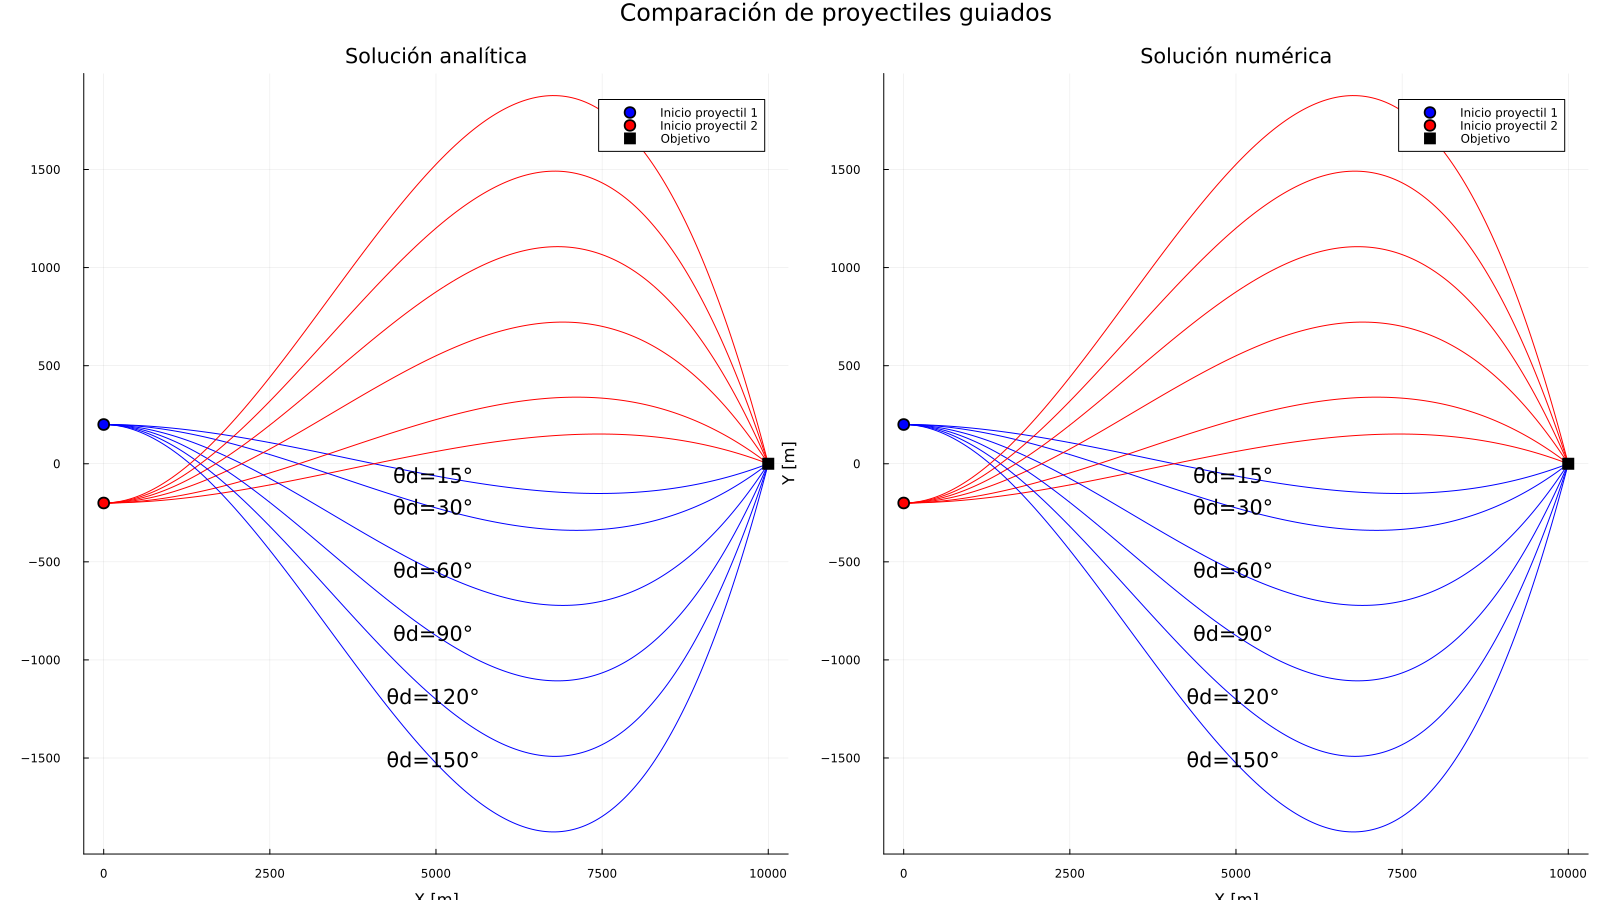

In [7]:
comparacion_angulos()